In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import random
import struct
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "cnn-improvements"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), "device": str(DEVICE), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "torch")}}
display(pd.Series(environment, name="Environment"))

python          3.12.0
device             mps
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
torch           2.14.1
Name: Environment, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = torch.from_numpy(images[train_indices].astype(np.float32) / 255.0).unsqueeze(1)
X_validation = torch.from_numpy(images[validation_indices].astype(np.float32) / 255.0).unsqueeze(1)
y_train = labels[train_indices]
y_validation = labels[validation_indices]
train_dataset = TensorDataset(X_train, torch.from_numpy(y_train.astype(np.int64)))
validation_dataset = TensorDataset(X_validation, torch.from_numpy(y_validation.astype(np.int64)))
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=512, shuffle=False, num_workers=0)
assert tuple(X_train.shape) == (48000, 1, 28, 28)
assert tuple(X_validation.shape) == (12000, 1, 28, 28)
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "shape": [str(tuple(X_train.shape)), str(tuple(X_validation.shape))]}))

,split,shape
0,Training,"(48000, 1, 28, 28)"
1,Validation,"(12000, 1, 28, 28)"


In [3]:
CONFIGS = [
    {"name": "original_extended", "channels": [16, 32], "hidden": 64, "weight_decay": 0.0},
    {"name": "wider", "channels": [32, 64], "hidden": 128, "weight_decay": 0.0},
    {"name": "wider_weight_decay", "channels": [32, 64], "hidden": 128, "weight_decay": 0.0001},
]
LEARNING_RATE = 0.001
MAX_EPOCHS = 30
PATIENCE = 5
criterion = nn.CrossEntropyLoss()

def build_model(config):
    first, second = config["channels"]
    return nn.Sequential(
        nn.Conv2d(1, first, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(first, second, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(second * 7 * 7, config["hidden"]), nn.ReLU(), nn.Dropout(0.25), nn.Linear(config["hidden"], 10),
    )

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

display(pd.DataFrame(CONFIGS))

,name,channels,hidden,weight_decay
0,original_extended,"[16, 32]",64,0.0000
1,wider,"[32, 64]",128,0.0000
2,wider_weight_decay,"[32, 64]",128,0.0001


In [4]:
@torch.inference_mode()
def evaluate(network, loader):
    network.eval()
    total_loss = 0.0
    probabilities = []
    targets = []
    for inputs, target in loader:
        inputs, target = inputs.to(DEVICE), target.to(DEVICE)
        logits = network(inputs)
        loss = criterion(logits, target)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite evaluation loss")
        total_loss += loss.item() * len(target)
        probabilities.append(logits.softmax(dim=1).cpu().numpy())
        targets.append(target.cpu().numpy())
    probabilities = np.concatenate(probabilities)
    targets = np.concatenate(targets)
    return total_loss / len(targets), accuracy_score(targets, probabilities.argmax(axis=1)), probabilities

In [5]:
baseline_dir = ROOT / "results" / "cnn-baseline"
baseline_metadata = json.loads((baseline_dir / "run-metadata.json").read_text())
assert baseline_metadata["split_sha256"] == split_sha256
baseline_path = baseline_dir / "best-model.pt"
assert hashlib.sha256(baseline_path.read_bytes()).hexdigest() == baseline_metadata["checkpoint_sha256"]
baseline_config = {"name": "original_baseline", "channels": [16, 32], "hidden": 64, "weight_decay": 0.0}
baseline_model = build_model(baseline_config).to(DEVICE)
baseline_model.load_state_dict(torch.load(baseline_path, map_location="cpu", weights_only=True))
baseline_loss, baseline_accuracy, baseline_probabilities = evaluate(baseline_model, validation_loader)
baseline_predictions = baseline_probabilities.argmax(axis=1)
baseline_saved = pd.read_csv(baseline_dir / "validation-predictions.csv")
np.testing.assert_array_equal(baseline_saved.source_index.to_numpy(), validation_indices)
np.testing.assert_array_equal(baseline_saved.predicted.to_numpy(), baseline_predictions)
rows = [{"name": "original_baseline", "train_accuracy": baseline_metadata["metrics"][0]["accuracy"],
         "validation_accuracy": baseline_accuracy, "validation_loss": baseline_loss,
         "validation_macro_f1": f1_score(y_validation, baseline_predictions, average="macro"),
         "shirt_recall": float((baseline_predictions[y_validation == 6] == 6).mean()),
         "parameter_count": baseline_metadata["parameter_count"], "selected_epoch": baseline_metadata["selected_epoch"],
         "epochs_run": baseline_metadata["epochs_run"], "training_seconds": baseline_metadata["training_seconds"]}]
checkpoints = {"original_baseline": baseline_path}
config_by_name = {"original_baseline": baseline_config, **{c["name"]: c for c in CONFIGS}}
histories = {}
for config in CONFIGS:
    reset_seed()
    model = build_model(config).to(DEVICE)
    parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2, threshold=0.0, min_lr=1e-5)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
    history = []
    best_loss, best_epoch, stale_epochs = float("inf"), 0, 0
    checkpoint_path = RESULTS / f"{config['name']}.pt"
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        learning_rate = optimizer.param_groups[0]["lr"]
        for inputs, target in train_loader:
            inputs, target = inputs.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(inputs), target)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss")
            loss.backward()
            optimizer.step()
        train_loss, train_accuracy, _ = evaluate(model, train_eval_loader)
        validation_loss, validation_accuracy, _ = evaluate(model, validation_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": validation_loss,
                        "train_accuracy": train_accuracy, "validation_accuracy": validation_accuracy, "learning_rate": learning_rate})
        if validation_loss < best_loss:
            best_loss, best_epoch, stale_epochs = validation_loss, epoch, 0
            torch.save({key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, checkpoint_path)
        else:
            stale_epochs += 1
        scheduler.step(validation_loss)
        pd.DataFrame(history).to_csv(RESULTS / f"{config['name']}-history.csv", index=False)
        print(f"{config['name']} epoch {epoch:02d}: validation accuracy={validation_accuracy:.4f}, loss={validation_loss:.4f}, best epoch={best_epoch}")
        if stale_epochs >= PATIENCE:
            break
    training_seconds = time.perf_counter() - start
    model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
    train_loss, train_accuracy, _ = evaluate(model, train_eval_loader)
    validation_loss, validation_accuracy, probabilities = evaluate(model, validation_loader)
    predictions = probabilities.argmax(axis=1)
    rows.append({"name": config["name"], "train_accuracy": train_accuracy,
                 "validation_accuracy": validation_accuracy, "validation_loss": validation_loss,
                 "validation_macro_f1": f1_score(y_validation, predictions, average="macro"),
                 "shirt_recall": float((predictions[y_validation == 6] == 6).mean()),
                 "parameter_count": parameter_count, "selected_epoch": best_epoch, "epochs_run": len(history),
                 "training_seconds": training_seconds})
    checkpoints[config["name"]] = checkpoint_path
    histories[config["name"]] = history
    pd.DataFrame(rows).to_csv(RESULTS / "comparison.csv", index=False)
comparison = pd.DataFrame(rows)
comparison["accuracy_gap"] = comparison.train_accuracy - comparison.validation_accuracy
display(comparison.round(4))

original_extended epoch 01: validation accuracy=0.8254, loss=0.4767, best epoch=1


original_extended epoch 02: validation accuracy=0.8598, loss=0.3893, best epoch=2


original_extended epoch 03: validation accuracy=0.8678, loss=0.3610, best epoch=3


original_extended epoch 04: validation accuracy=0.8785, loss=0.3274, best epoch=4


original_extended epoch 05: validation accuracy=0.8808, loss=0.3222, best epoch=5


...

wider_weight_decay epoch 19: validation accuracy=0.9247, loss=0.2267, best epoch=17


wider_weight_decay epoch 20: validation accuracy=0.9258, loss=0.2226, best epoch=17


wider_weight_decay epoch 21: validation accuracy=0.9268, loss=0.2248, best epoch=17


wider_weight_decay epoch 22: validation accuracy=0.9259, loss=0.2328, best epoch=17


,name,train_accuracy,validation_accuracy,validation_loss,validation_macro_f1,shirt_recall,parameter_count,selected_epoch,epochs_run,training_seconds,accuracy_gap
0,original_baseline,0.9270,0.9070,0.2567,0.9066,0.7033,105866,14,15,36.5427,0.0200
1,original_extended,0.9446,0.9145,0.2431,0.9142,0.7250,105866,23,28,61.3502,0.0301
2,wider,0.9567,0.9233,0.2218,0.9225,0.7208,421642,12,17,56.3279,0.0333
3,wider_weight_decay,0.9692,0.9228,0.2188,0.9226,0.7783,421642,17,22,72.1261,0.0465


In [6]:
selected = comparison.sort_values(["validation_accuracy", "validation_loss", "parameter_count"], ascending=[False, True, True]).iloc[0]
selected_name = selected["name"]
selected_config = config_by_name[selected_name]
model = build_model(selected_config).to(DEVICE)
model.load_state_dict(torch.load(checkpoints[selected_name], map_location="cpu", weights_only=True))
training_loss, training_accuracy, train_probabilities = evaluate(model, train_eval_loader)
validation_loss, validation_accuracy, validation_probabilities = evaluate(model, validation_loader)
validation_predictions = validation_probabilities.argmax(axis=1)
metrics_table = pd.DataFrame([
    {"split": "Training", "accuracy": training_accuracy, "macro_f1": f1_score(y_train, train_probabilities.argmax(axis=1), average="macro"), "loss": training_loss},
    {"split": "Validation", "accuracy": validation_accuracy, "macro_f1": f1_score(y_validation, validation_predictions, average="macro"), "loss": validation_loss},
]).set_index("split")
report = classification_report(y_validation, validation_predictions, labels=np.arange(10), target_names=CLASS_NAMES.tolist(), output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
per_class["support"] = per_class["support"].astype(int)
print(f"Selected: {selected_name}; epoch {int(selected.selected_epoch)}")
print(f"Accuracy improvement over baseline: {100*(validation_accuracy-baseline_accuracy):.2f} percentage points")
display(metrics_table.round(4))
display(per_class.round(4))

Selected: wider; epoch 12
Accuracy improvement over baseline: 1.63 percentage points


,accuracy,macro_f1,loss
split,,,
Training,0.9567,0.9562,0.1235
Validation,0.9233,0.9225,0.2218


,precision,recall,f1-score,support
T-shirt/top,0.8551,0.8800,0.8674,1200
Trouser,0.9875,0.9900,0.9888,1200
Pullover,0.8675,0.9167,0.8914,1200
Dress,0.9167,0.9267,0.9217,1200
Coat,0.8622,0.9017,0.8815,1200
Sandal,0.9907,0.9775,0.9841,1200
Shirt,0.8539,0.7208,0.7817,1200
Sneaker,0.9600,0.9608,0.9604,1200
Bag,0.9778,0.9900,0.9839,1200
Ankle boot,0.9588,0.9692,0.9639,1200


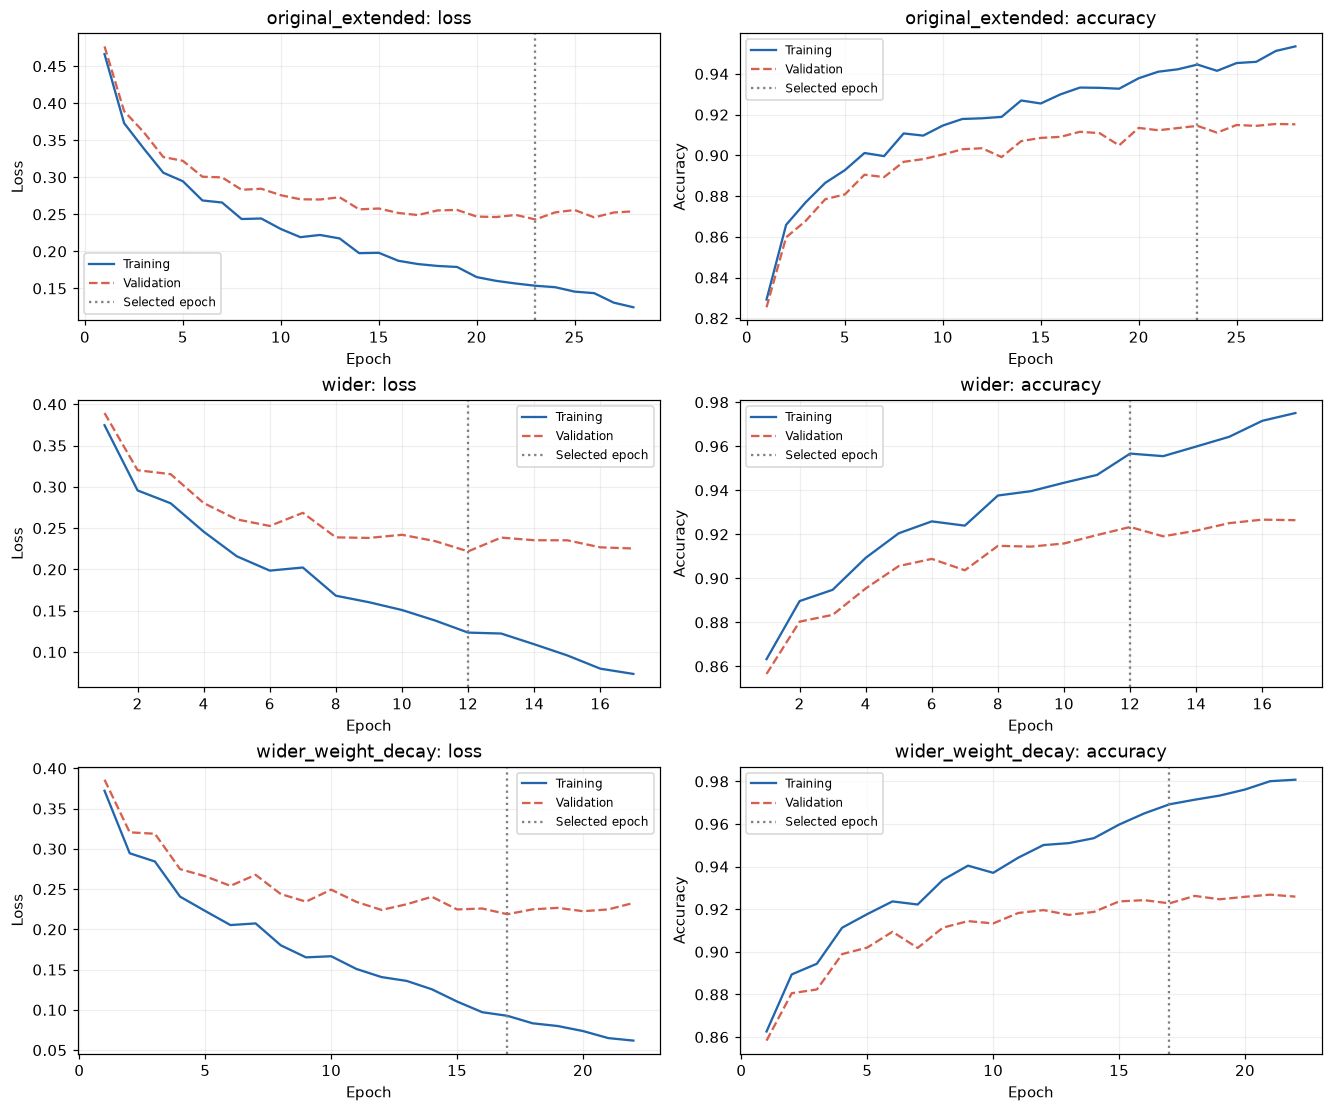

In [7]:
fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(12, 10), layout="constrained")
for config, row_axes in zip(CONFIGS, axes):
    table = pd.DataFrame(histories[config["name"]])
    best_epoch = int(comparison.loc[comparison.name == config["name"], "selected_epoch"].iloc[0])
    for ax, metric in zip(row_axes, ["loss", "accuracy"]):
        ax.plot(table.epoch, table[f"train_{metric}"], label="Training", color="#2166ac")
        ax.plot(table.epoch, table[f"validation_{metric}"], label="Validation", color="#d6604d", linestyle="--")
        ax.axvline(best_epoch, color="gray", linestyle=":", label="Selected epoch")
        ax.set(title=f"{config['name']}: {metric}", xlabel="Epoch", ylabel=metric.capitalize())
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
fig.savefig(RESULTS / "experiment-curves.png", bbox_inches="tight")
plt.show()

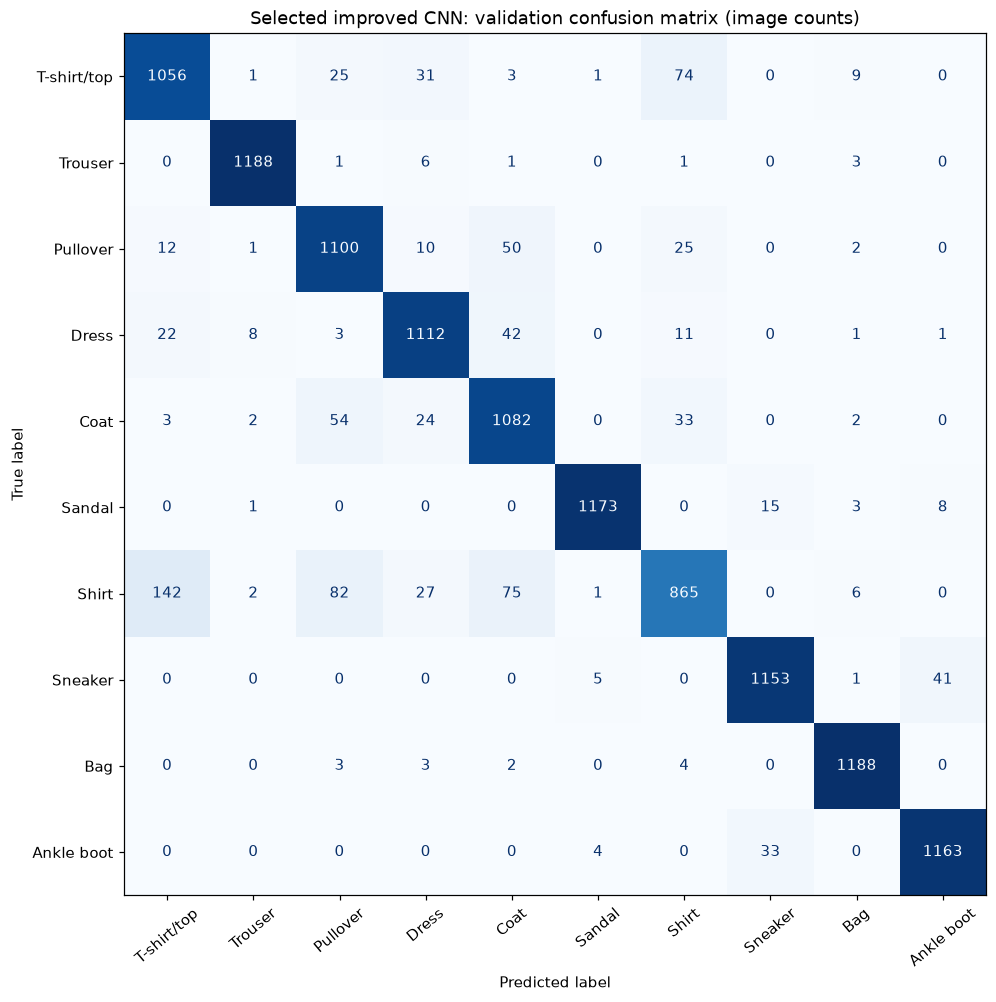

,actual,predicted,images,share_of_actual_class
0,Shirt,T-shirt/top,142,0.1183
1,Shirt,Pullover,82,0.0683
2,Shirt,Coat,75,0.0625
3,T-shirt/top,Shirt,74,0.0617
4,Coat,Pullover,54,0.0450
5,Pullover,Coat,50,0.0417
6,Dress,Coat,42,0.0350
7,Sneaker,Ankle boot,41,0.0342
8,Coat,Shirt,33,0.0275
9,Ankle boot,Sneaker,33,0.0275


In [8]:
matrix = confusion_matrix(y_validation, validation_predictions, labels=np.arange(10))
assert matrix.sum() == len(y_validation)
assert np.isclose(np.trace(matrix) / matrix.sum(), metrics_table.loc["Validation", "accuracy"])
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=40, colorbar=False)
ax.set_title("Selected improved CNN: validation confusion matrix (image counts)")
fig.savefig(RESULTS / "validation-confusion-matrix.png", bbox_inches="tight")
plt.show()
confusions = pd.DataFrame([
    {"actual": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "images": int(matrix[i,j]), "share_of_actual_class": float(matrix[i,j] / matrix[i].sum())}
    for i in range(10) for j in range(10) if i != j and matrix[i,j] > 0
]).sort_values("images", ascending=False).reset_index(drop=True)
display(confusions.head(10).round(4))

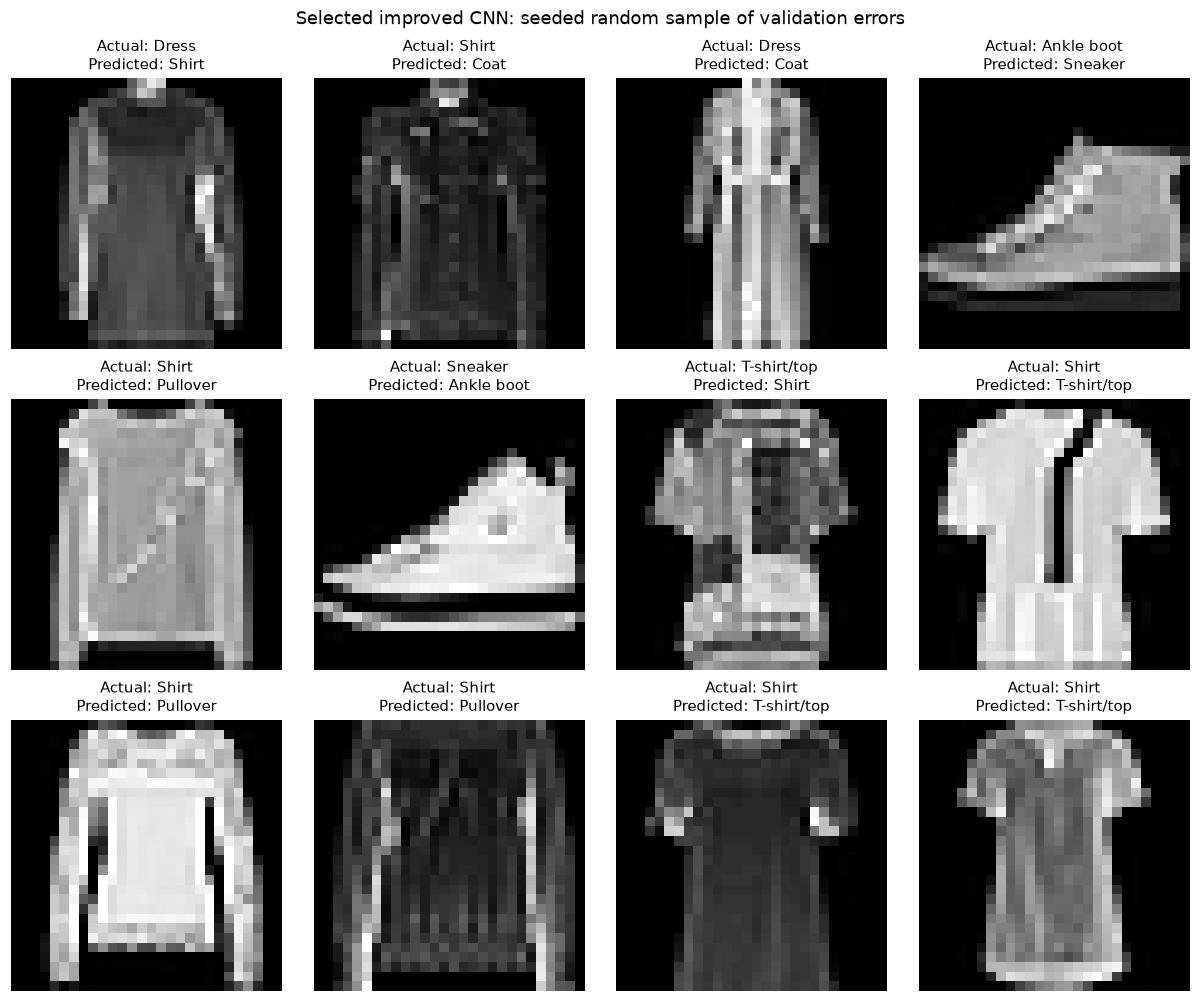

In [9]:
error_positions = np.flatnonzero(validation_predictions != y_validation)
rng = np.random.default_rng(SEED)
selected = rng.choice(error_positions, size=min(12, len(error_positions)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(11, 9), layout="constrained")
for ax in axes.ravel():
    ax.axis("off")
for ax, position in zip(axes.ravel(), selected):
    ax.imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Actual: {CLASS_NAMES[y_validation[position]]}\nPredicted: {CLASS_NAMES[validation_predictions[position]]}", fontsize=10)
fig.suptitle("Selected improved CNN: seeded random sample of validation errors")
fig.savefig(RESULTS / "validation-errors.png", bbox_inches="tight")
plt.show()

In [10]:
selected_path = RESULTS / "selected-model.pt"
torch.save({key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, selected_path)
restored = build_model(selected_config).to(DEVICE)
restored.load_state_dict(torch.load(selected_path, map_location="cpu", weights_only=True))
_, _, restored_probabilities = evaluate(restored, validation_loader)
np.testing.assert_array_equal(restored_probabilities.argmax(axis=1), validation_predictions)
np.testing.assert_allclose(restored_probabilities, validation_probabilities, rtol=1e-5, atol=1e-6)
comparison.to_csv(RESULTS / "comparison.csv", index=False)
metrics_table.to_csv(RESULTS / "selected-metrics.csv")
per_class.to_csv(RESULTS / "selected-classification-report.csv")
confusions.to_csv(RESULTS / "validation-confusions.csv", index=False)
pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": validation_predictions,
              "predicted_probability": validation_probabilities.max(axis=1)}).to_csv(RESULTS / "validation-predictions.csv", index=False)
metadata = {"configs": CONFIGS, "selected_name": selected_name, "selected_config": selected_config,
            "seed": SEED, "environment": environment, "source_files": training_files, "split_sha256": split_sha256,
            "preprocessing": "float32 pixels / 255; N x 1 x 28 x 28", "class_names": CLASS_NAMES.tolist(),
            "batch_size": BATCH_SIZE, "dropout": 0.25, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
            "optimizer": "Adam", "initial_learning_rate": LEARNING_RATE,
            "scheduler": {"name": "ReduceLROnPlateau", "factor": 0.5, "patience": 2, "threshold": 0.0, "min_lr": 1e-5},
            "checkpoint_selection": "Lowest validation loss per run",
            "candidate_selection": "Highest validation accuracy, then lower validation loss, then fewer parameters",
            "comparisons": comparison.to_dict(orient="records"), "test_evaluated": False,
            "training_count": len(y_train), "validation_count": len(y_validation),
            "selected_checkpoint_sha256": hashlib.sha256(selected_path.read_bytes()).hexdigest()}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/cnn-improvements artifacts")
print("Reloaded selected model reproduces all validation predictions")

Saved results/cnn-improvements artifacts
Reloaded selected model reproduces all validation predictions
